# Is the hypoxia–FLT1 coupling stronger in preeclampsia than in growth restriction? (Addendum E)

Addendum E (primary test **E1**, robustness **E2**) was committed before this notebook was run.
Run notebooks 01–05 first (this notebook re-derives scores itself and reads the downloaded GSE114691 files).

In [1]:
import os, sys, warnings
from pathlib import Path
if "google.colab" in sys.modules:
    os.chdir("/content/team/notebooks")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path(".."); EXT = ROOT / "data_external"
DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(EXT / "h.all.v2024.1.Hs.symbols.gmt")}
HYP, GLY = set(gmt["HALLMARK_HYPOXIA"]), set(gmt["HALLMARK_GLYCOLYSIS"])
SETS = {"hyp_all": HYP, "shared": HYP & GLY, "hyp_only": HYP - GLY, "gly_only": GLY - HYP}
assert "FLT1" not in HYP

def vst_of(counts, groups):
    counts = counts.loc[(counts >= 10).sum(axis=1) >= 5]
    md = pd.DataFrame({"g": groups}, index=counts.columns)
    dds = DeseqDataSet(counts=counts.T.astype(int), metadata=md, design="~g", inference=DefaultInference(n_cpus=4), quiet=True)
    dds.fit_size_factors(); dds.vst(use_design=False)
    return pd.DataFrame(dds.layers["vst_counts"], index=counts.columns, columns=counts.index)

def scores(vst, genes_allowed=None):
    z = (vst - vst.mean()) / vst.std()
    out = {}
    for k, v in SETS.items():
        g = sorted(x for x in v if x in z.columns and (genes_allowed is None or x in genes_allowed))
        out[k] = z[g].mean(axis=1)
    return pd.DataFrame(out)

# Discovery cohort (GSE203507)
counts = pd.read_csv(DATA_DIR / "track01_counts_vt.csv", index_col=0)
meta = pd.read_csv(DATA_DIR / "track01_metadata_vt.csv", index_col=0).loc[counts.columns]
vst_d = vst_of(counts, meta.pe_status.values)

# Replication cohort (GSE114691), same processing as notebook 05
tx2gene = pd.read_csv(EXT / "grch37_tx2gene.tsv", sep="\t").set_index("Transcript stable ID")["Gene name"]
parts = []
for g, f in {"control": "ControlONLY", "IUGR": "IUGRONLY", "PE": "PEONLY", "PE+IUGR": "PEIUGR"}.items():
    d = pd.read_csv(EXT / f"GSE114691_MasterCount_{f}.txt.gz", sep="\t", index_col=0); d.columns = [f"{g}|{c}" for c in d.columns]; parts.append(d)
tx = pd.concat(parts, axis=1); m = tx.index.isin(tx2gene.index)
gc_r = tx[m].groupby(tx2gene.reindex(tx.index[m]).values).sum().round().astype(int)
meta_r = pd.DataFrame({"group": [c.split("|")[0] for c in gc_r.columns]}, index=gc_r.columns)
meta_r["PE"] = meta_r.group.str.startswith("PE").astype(int)
vst_r = vst_of(gc_r, meta_r.PE.values)

# Syncytiotrophoblast marker score (for the composition check)
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")
STB_MARKERS = sorted(markers.loc[markers.cell_class == "syncytiotrophoblast", "gene_symbol"])
def stb_score(vst):
    z = (vst - vst.mean()) / vst.std(); g = [x for x in STB_MARKERS if x in z.columns]
    return z[g].mean(axis=1), g
print("STB markers:", STB_MARKERS)

STB markers: ['CGA', 'CGB', 'ERVW-1', 'PSG1']


## E1. Primary: GSE114691, PE (40) + IUGR-only (18): `FLT1 ~ hyp_z * PE`

In [2]:
def coupling_model(vst, md, extra="", genes_allowed=None, add_stb=False, cov_type="nonrobust"):
    S = scores(vst, genes_allowed)
    d = md.copy(); d["FLT1"] = vst.loc[d.index, "FLT1"]; d["hyp"] = S.loc[d.index, "hyp_all"]
    d["hyp_z"] = (d.hyp - d.hyp.mean()) / d.hyp.std()
    form = "FLT1 ~ hyp_z * PE" + extra
    if add_stb:
        s, _ = stb_score(vst); d["stb"] = s.loc[d.index]; form += " + stb"
    f = smf.ols(form, data=d).fit(cov_type=cov_type)
    L_pe = np.zeros(len(f.params)); L_pe[list(f.params.index).index("hyp_z")] = 1; L_pe[list(f.params.index).index("hyp_z:PE")] = 1
    tpe = f.t_test(L_pe)
    return {"n": len(d), "n_PE": int(d.PE.sum()), "n_FGR": int((1 - d.PE).sum()),
            "slope_FGR": f.params["hyp_z"], "slope_PE": float(tpe.effect[0]),
            "interaction": f.params["hyp_z:PE"], "int_CI_low": f.conf_int().loc["hyp_z:PE", 0],
            "int_CI_high": f.conf_int().loc["hyp_z:PE", 1], "int_p": f.pvalues["hyp_z:PE"],
            # descriptive, NOT pre-specified: PE offset in FLT1 at average hypoxia score
            "PE_offset_at_mean_hyp": f.params["PE"], "offset_CI_low": f.conf_int().loc["PE", 0],
            "offset_CI_high": f.conf_int().loc["PE", 1], "offset_p": f.pvalues["PE"]}, d

md_r = meta_r[meta_r.group != "control"][["PE"]]
md_d = meta.loc[meta.group.isin(["EOPE", "EOPE+FGR", "FGR"]), ["ga_delivery_weeks", "fetal_sex"]].copy()
md_d["PE"] = meta.loc[md_d.index, "pe_status"].eq("PE").astype(int)

rows = []
res, d_r = coupling_model(vst_r, md_r); rows.append({"analysis": "PRIMARY GSE114691", **res})
res, _ = coupling_model(vst_r, md_r, cov_type="HC3"); rows.append({"analysis": "GSE114691, HC3 SE", **res})
res, _ = coupling_model(vst_r, md_r, add_stb=True); rows.append({"analysis": "GSE114691 + STB marker score", **res})
res, d_d = coupling_model(vst_d, md_d, extra=" + ga_delivery_weeks + C(fetal_sex)"); rows.append({"analysis": "Secondary GSE203507 (+GA, sex)", **res})
res, _ = coupling_model(vst_d, md_d, extra=" + ga_delivery_weeks + C(fetal_sex)", add_stb=True); rows.append({"analysis": "GSE203507 + STB marker score", **res})
e1 = pd.DataFrame(rows); e1.to_csv(RES_DIR / "E1_coupling_interaction.csv", index=False)
pd.set_option("display.width", 220)
print(e1.round(3).to_string(index=False))

p = e1.iloc[0]
if p.int_p < 0.05 and p.interaction > 0:
    verdict = "coupling STRONGER in PE"
elif p.int_CI_low <= 0 <= p.int_CI_high and p.int_CI_high < p.slope_PE:
    verdict = "coupling SIMILAR in PE and growth restriction (CI excludes differences as large as the PE slope)"
else:
    verdict = "INCONCLUSIVE"
print("\nPre-specified verdict (primary):", verdict)

sp = []
for cohort, d in [("GSE114691", d_r), ("GSE203507", d_d)]:
    for lab, sub in [("PE", d[d.PE == 1]), ("growth restriction only", d[d.PE == 0])]:
        r, pv = stats.spearmanr(sub.hyp, sub.FLT1); sp.append({"cohort": cohort, "group": lab, "n": len(sub), "rho": r, "p": pv})
sp = pd.DataFrame(sp); sp.to_csv(RES_DIR / "E1_within_group_spearman.csv", index=False); print(sp.round(3).to_string(index=False))

                      analysis  n  n_PE  n_FGR  slope_FGR  slope_PE  interaction  int_CI_low  int_CI_high  int_p  PE_offset_at_mean_hyp  offset_CI_low  offset_CI_high  offset_p
             PRIMARY GSE114691 58    40     18      0.789     0.477       -0.313      -0.917        0.292  0.304                  1.065          0.501           1.630     0.000
             GSE114691, HC3 SE 58    40     18      0.789     0.477       -0.313      -1.423        0.798  0.581                  1.065          0.220           1.911     0.014
  GSE114691 + STB marker score 58    40     18      1.121     0.510       -0.611      -1.133       -0.089  0.023                  0.615          0.106           1.124     0.019
Secondary GSE203507 (+GA, sex) 20    15      5      2.603     0.819       -1.785      -3.870        0.301  0.088                 -0.458         -2.317           1.401     0.605
  GSE203507 + STB marker score 20    15      5      2.361     0.868       -1.493      -3.756        0.770  0.178   

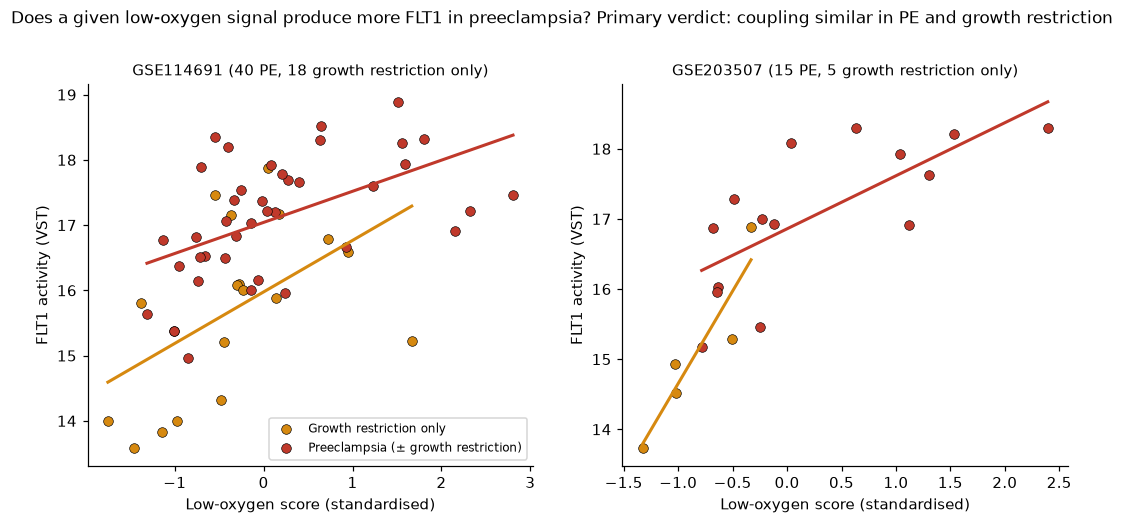

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
for ax, (d, title) in zip(axes, [(d_r, "GSE114691 (40 PE, 18 growth restriction only)"), (d_d, "GSE203507 (15 PE, 5 growth restriction only)")]):
    for pe, col, lab in [(0, "#d68910", "Growth restriction only"), (1, "#c0392b", "Preeclampsia (± growth restriction)")]:
        sub = d[d.PE == pe]
        ax.scatter(sub.hyp_z, sub.FLT1, c=col, s=40, edgecolor="k", lw=0.4, label=lab)
        b = np.polyfit(sub.hyp_z, sub.FLT1, 1); xs = np.linspace(sub.hyp_z.min(), sub.hyp_z.max(), 10)
        ax.plot(xs, np.polyval(b, xs), c=col, lw=2)
    ax.set_xlabel("Low-oxygen score (standardised)"); ax.set_ylabel("FLT1 activity (VST)"); ax.set_title(title, fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle(f"Does a given low-oxygen signal produce more FLT1 in preeclampsia? Primary verdict: {verdict.split(' (')[0].replace('SIMILAR', 'similar').replace('STRONGER', 'stronger')}", y=1.03, fontsize=11)
plt.savefig(FIG_DIR / "fig11_coupling_PE_vs_FGR.png", dpi=300, bbox_inches="tight"); plt.show()

## E2a. Robustness: identical gene sets in both cohorts

In [4]:
common = set(vst_d.columns) & set(vst_r.columns)
for k, v in SETS.items():
    print(f"{k:<9} common genes: {len([g for g in v if g in common])} (discovery {len([g for g in v if g in vst_d.columns])}, replication {len([g for g in v if g in vst_r.columns])})")
rows = []
Sd = scores(vst_d, common).join(meta[["group", "ga_delivery_weeks", "fetal_sex"]])
Sd = Sd[Sd.group != "TB"]; Sd["grp"] = Sd.group.map({"iPTB": "ctrl", "EOPE": "EOPE", "EOPE+FGR": "EOPEFGR", "FGR": "FGR"})
Sr = scores(vst_r, common).join(meta_r[["group"]]); Sr["grp"] = Sr.group.map({"control": "ctrl", "PE": "EOPE", "PE+IUGR": "EOPEFGR", "IUGR": "FGR"})
for cohort, S, extra in [("GSE203507", Sd, " + ga_delivery_weeks + C(fetal_sex)"), ("GSE114691", Sr, "")]:
    for y in ["hyp_only", "shared", "gly_only", "hyp_all"]:
        f = smf.ols(f"{y} ~ C(grp, Treatment('ctrl'))" + extra, data=S).fit()
        nm = {g: f"C(grp, Treatment('ctrl'))[T.{g}]" for g in ["EOPE", "EOPEFGR", "FGR"]}
        for cname, w in {"EOPE vs control": {nm["EOPE"]: 1}, "PE (both) vs growth restriction": {nm["EOPE"]: .5, nm["EOPEFGR"]: .5, nm["FGR"]: -1}}.items():
            L = np.zeros(len(f.params))
            for kk, vv in w.items(): L[list(f.params.index).index(kk)] = vv
            t = f.t_test(L); ci = t.conf_int()[0]
            rows.append({"cohort": cohort, "score": y, "contrast": cname, "estimate": float(t.effect[0]), "CI_low": ci[0], "CI_high": ci[1], "p": float(t.pvalue)})
e2a = pd.DataFrame(rows)
res, _ = coupling_model(vst_r, md_r, genes_allowed=common)
e2a = pd.concat([e2a, pd.DataFrame([{"cohort": "GSE114691", "score": "hyp_all", "contrast": "E1 interaction (common genes)",
                                     "estimate": res["interaction"], "CI_low": res["int_CI_low"], "CI_high": res["int_CI_high"], "p": res["int_p"]}])])
e2a.to_csv(RES_DIR / "E2a_common_genes.csv", index=False)
e2a["txt"] = e2a.estimate.round(2).astype(str) + " [" + e2a.CI_low.round(2).astype(str) + ", " + e2a.CI_high.round(2).astype(str) + "] p=" + e2a.p.round(3).astype(str)
print(e2a.pivot_table(index=["cohort", "contrast"], columns="score", values="txt", aggfunc="first").to_string())

hyp_all   common genes: 174 (discovery 177, replication 183)
shared    common genes: 58 (discovery 59, replication 62)
hyp_only  common genes: 116 (discovery 118, replication 121)
gly_only  common genes: 118 (discovery 118, replication 126)
score                                                         gly_only                      hyp_all                    hyp_only                     shared
cohort    contrast                                                                                                                                        
GSE114691 E1 interaction (common genes)                            NaN  -0.34 [-0.94, 0.27] p=0.272                         NaN                        NaN
          EOPE vs control                  -0.2 [-0.32, -0.08] p=0.002    0.28 [0.11, 0.46] p=0.002   0.23 [0.08, 0.39] p=0.004   0.38 [0.15, 0.6] p=0.001
          PE (both) vs growth restriction    0.01 [-0.1, 0.12] p=0.889    0.15 [-0.01, 0.3] p=0.069  0.12 [-0.02, 0.26] p=0.095    0.2 [-0.

## E2b. Leave-one-out

In [5]:
loo = []
for i in d_r.index:
    sub = d_r.drop(index=i); f = smf.ols("FLT1 ~ hyp_z * PE", data=sub).fit()
    loo.append(f.params["hyp_z:PE"])
loo = np.array(loo)
rows = [{"test": "E1 interaction (GSE114691)", "n": len(d_r), "full": e1.iloc[0].interaction, "loo_min": loo.min(), "loo_max": loo.max(),
         "sign_flips": int((np.sign(loo) != np.sign(e1.iloc[0].interaction)).sum())}]
pb = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_counts.csv", index_col=0)
pbm = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_metadata.csv", index_col=0)
mdp = pbm[(pbm.cell_class == "syncytiotrophoblast") & (pbm.clinical_group == "PE_early")]
c = pb[mdp.index]; c = c.loc[(c >= 10).sum(axis=1) >= 3]; lc = np.log2(c / c.sum() * 1e6 + 1)
zz = lc.sub(lc.mean(1), axis=0).div(lc.std(1).replace(0, np.nan), axis=0)
stb = pd.DataFrame({"hyp": zz.loc[zz.index.intersection(sorted(HYP))].mean(), "FLT1": lc.loc["FLT1"]})
Sd_all = scores(vst_d); Sr_all = scores(vst_r)
for lab, h, fl in [("within-PE rho, GSE203507 (n=15)", Sd_all.loc[meta.index[meta.pe_status == "PE"], "hyp_all"], vst_d.loc[meta.index[meta.pe_status == "PE"], "FLT1"]),
                   ("within-PE rho, GSE114691 (n=40)", Sr_all.loc[meta_r.index[meta_r.PE == 1], "hyp_all"], vst_r.loc[meta_r.index[meta_r.PE == 1], "FLT1"]),
                   ("within-early-PE rho, single-cell STB (n=10)", stb.hyp, stb.FLT1)]:
    full = stats.spearmanr(h, fl)[0]
    vals = np.array([stats.spearmanr(h.drop(index=i), fl.drop(index=i))[0] for i in h.index])
    rows.append({"test": lab, "n": len(h), "full": full, "loo_min": vals.min(), "loo_max": vals.max(), "sign_flips": int((np.sign(vals) != np.sign(full)).sum())})
e2b = pd.DataFrame(rows); e2b.to_csv(RES_DIR / "E2b_leave_one_out.csv", index=False); print(e2b.round(3).to_string(index=False))

                                       test  n   full  loo_min  loo_max  sign_flips
                 E1 interaction (GSE114691) 58 -0.313   -0.809   -0.182           0
            within-PE rho, GSE203507 (n=15) 15  0.779    0.727    0.846           0
            within-PE rho, GSE114691 (n=40) 40  0.593    0.563    0.643           0
within-early-PE rho, single-cell STB (n=10) 10  0.842    0.783    0.883           0
